# UCI Online Retail — Exploratory Data Analysis and Business Insights

## Project Overview

This project explores online retail transactions to understand revenue trends, product performance, country-wise sales, and customer purchasing patterns using Python.

## Business Problem

An online retailer generates a large number of transactions, making it difficult to identify important sales patterns by looking at raw data alone. The business needs a clearer view of its best-performing products, key markets, monthly sales trends, and unusual transactions.

This analysis uses exploratory data analysis (EDA) to turn transaction data into useful information that can support sales planning and business decisions.

## Project Objectives

Clean and inspect the dataset.

Identify missing values, duplicates, and potential outliers.

Analyze revenue by country, product, month, and customer.

Investigate cancellations, returns, and unusual transactions.

Develop business insights from the findings.findings in simple visualizations and suggest practical business actions.

## Dataset and Source

Source: UCI Machine Learning Repository

Original records: 541,909 rows and 8 columns

Period: December 2010 – December 2011 (incomplete month)

Key columns: InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID, Country

## Tools and Technologies

Python, Pandas, NumPy, Matplotlib, Seaborn, and Jupyter Notebook.

## Data Cleaning and Preparation

Removed 5,268 duplicate rows, leaving 536,641 records.

Examined missing CustomerID and product descriptions.

Created a Revenue column using Quantity × UnitPrice.

Investigated negative quantities, prices, zero-value transactions, and potential outliers.

Retained unusual values for investigation rather than automatically removing them.

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel("DATA/Online Retail.xlsx", sheet_name="Online Retail")

In [3]:
df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


In [4]:
df.shape

(541909, 8)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [6]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [7]:
df.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

In [8]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [9]:
df[df["CustomerID"].isnull()].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom


In [10]:
df["CustomerID"].isnull().sum()

np.int64(135080)

In [11]:
df[df["Description"].isnull()].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom


In [12]:
df["Description"].isnull().sum()

np.int64(1454)

In [13]:
df["Country"].unique()

array(['United Kingdom', 'France', 'Australia', 'Netherlands', 'Germany',
       'Norway', 'EIRE', 'Switzerland', 'Spain', 'Poland', 'Portugal',
       'Italy', 'Belgium', 'Lithuania', 'Japan', 'Iceland',
       'Channel Islands', 'Denmark', 'Cyprus', 'Sweden', 'Austria',
       'Israel', 'Finland', 'Bahrain', 'Greece', 'Hong Kong', 'Singapore',
       'Lebanon', 'United Arab Emirates', 'Saudi Arabia',
       'Czech Republic', 'Canada', 'Unspecified', 'Brazil', 'USA',
       'European Community', 'Malta', 'RSA'], dtype=object)

In [14]:
df["Country"].nunique()

38

In [15]:
df.duplicated().sum()

np.int64(5268)

In [16]:
df.count().duplicated()

InvoiceNo      False
StockCode       True
Description    False
Quantity        True
InvoiceDate     True
UnitPrice       True
CustomerID     False
Country         True
dtype: bool

In [17]:
df[df.duplicated()]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
...,...,...,...,...,...,...,...,...
541675,581538,22068,BLACK PIRATE TREASURE CHEST,1,2011-12-09 11:34:00,0.39,14446.0,United Kingdom
541689,581538,23318,BOX OF 6 MINI VINTAGE CRACKERS,1,2011-12-09 11:34:00,2.49,14446.0,United Kingdom
541692,581538,22992,REVOLVER WOODEN RULER,1,2011-12-09 11:34:00,1.95,14446.0,United Kingdom
541699,581538,22694,WICKER STAR,1,2011-12-09 11:34:00,2.10,14446.0,United Kingdom


In [18]:
df[df.duplicated()].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
587,536412,22273,FELTCRAFT DOLL MOLLY,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
589,536412,22749,FELTCRAFT PRINCESS CHARLOTTE DOLL,1,2010-12-01 11:49:00,3.75,17920.0,United Kingdom
594,536412,22141,CHRISTMAS CRAFT TREE TOP ANGEL,1,2010-12-01 11:49:00,2.10,17920.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
600,536412,22569,FELTCRAFT CUSHION BUTTERFLY,2,2010-12-01 11:49:00,3.75,17920.0,United Kingdom


In [19]:
df[df.duplicated(keep=False)].head(20)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [20]:
df.shape

(541909, 8)

In [21]:
df.drop_duplicates().shape

(536641, 8)

In [22]:
df["InvoiceDate"].head(10)

0   2010-12-01 08:26:00
1   2010-12-01 08:26:00
2   2010-12-01 08:26:00
3   2010-12-01 08:26:00
4   2010-12-01 08:26:00
5   2010-12-01 08:26:00
6   2010-12-01 08:26:00
7   2010-12-01 08:28:00
8   2010-12-01 08:28:00
9   2010-12-01 08:34:00
Name: InvoiceDate, dtype: datetime64[ns]

In [23]:
df["InvoiceDate"].tail(10)

541899   2011-12-09 12:50:00
541900   2011-12-09 12:50:00
541901   2011-12-09 12:50:00
541902   2011-12-09 12:50:00
541903   2011-12-09 12:50:00
541904   2011-12-09 12:50:00
541905   2011-12-09 12:50:00
541906   2011-12-09 12:50:00
541907   2011-12-09 12:50:00
541908   2011-12-09 12:50:00
Name: InvoiceDate, dtype: datetime64[ns]

In [24]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [25]:
df["InvoiceNo"].nunique()

25900

In [26]:
df["CustomerID"].count()

np.int64(406829)

In [27]:
df["CustomerID"].nunique()

4372

In [28]:
df["InvoiceDate"].min()

Timestamp('2010-12-01 08:26:00')

In [29]:
df["InvoiceDate"].max()

Timestamp('2011-12-09 12:50:00')

In [30]:
df[["Quantity", "UnitPrice"]].agg(["min", "max"])

,Quantity,UnitPrice
min,-80995,-11062.06
max,80995,38970.00


In [31]:
df[df.duplicated(keep=False)].sort_values(
    by=["InvoiceNo", "StockCode", "CustomerID"]
).head(20)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


In [32]:
df.duplicated(keep=False)

0         False
1         False
2         False
3         False
4         False
          ...  
541904    False
541905    False
541906    False
541907    False
541908    False
Length: 541909, dtype: bool

In [33]:
df.duplicated().sum()

np.int64(5268)

In [34]:
df.drop_duplicates().shape

(536641, 8)

In [35]:
df[df["Quantity"]< 0].head(20)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [36]:
df[df["Quantity"]< 0].count()

InvoiceNo      10624
StockCode      10624
Description     9762
Quantity       10624
InvoiceDate    10624
UnitPrice      10624
CustomerID      8905
Country        10624
dtype: int64

In [37]:
df[df["Quantity"]< 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397.0,United Kingdom
541541,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498.0,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311.0,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315.0,United Kingdom


In [38]:
df[df["UnitPrice"]< 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [39]:
df[df["Description"].isnull()]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
535322,581199,84581,NaN,-2,2011-12-07 18:26:00,0.0,NaN,United Kingdom
535326,581203,23406,NaN,15,2011-12-07 18:31:00,0.0,NaN,United Kingdom
535332,581209,21620,NaN,6,2011-12-07 18:35:00,0.0,NaN,United Kingdom
536981,581234,72817,NaN,27,2011-12-08 10:33:00,0.0,NaN,United Kingdom


In [40]:
df[df["Description"].isnull()]["CustomerID"].isnull().sum()

np.int64(1454)

In [41]:
df[df["Description"].isnull()]["StockCode"].value_counts().head(20)

StockCode
23084     10
35965     10
22084      9
22451      6
22501      5
21784      5
21033      5
22866      5
23348      5
21067      5
20975      4
79164      4
22444      4
22034      4
84534B     4
20713      4
21667      4
71477      4
82583      4
23284      4
Name: count, dtype: int64

In [42]:
df.loc[df["Description"].isnull(), "StockCode"].head(10)

622      22139
1970     21134
1971     22145
1972     37509
1987    85226A
1988     85044
2024     20950
2025     37461
2026     84670
2406     21777
Name: StockCode, dtype: object

In [43]:
df.loc[df["StockCode"] == 20713, "Description"].value_counts(dropna=False).head(10)

Description
JUMBO BAG OWLS                  673
NaN                               4
wrongly marked. 23343 in box      1
wrongly coded-23343               1
found                             1
Found                             1
wrongly marked 23343              1
Marked as 23343                   1
wrongly coded 23343               1
Name: count, dtype: int64

In [44]:
df_clean = df.drop_duplicates().copy()
df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [45]:
df_clean.shape

(536641, 8)

In [46]:
df_clean[df_clean["Description"].isnull()]["CustomerID"].isnull().sum()

np.int64(1454)

In [47]:
df_clean.loc[df_clean["StockCode"] == 20713, "Description"].value_counts(dropna=False).head(10)

Description
JUMBO BAG OWLS                  668
NaN                               4
wrongly marked. 23343 in box      1
wrongly coded-23343               1
found                             1
Found                             1
wrongly marked 23343              1
Marked as 23343                   1
wrongly coded 23343               1
Name: count, dtype: int64

In [48]:
df_clean["CustomerID"].isnull().sum()

np.int64(135037)

In [49]:
df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [50]:
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

In [51]:
df_clean["Revenue"]

0         15.30
1         20.34
2         22.00
3         20.34
4         20.34
          ...  
541904    10.20
541905    12.60
541906    16.60
541907    16.60
541908    14.85
Name: Revenue, Length: 536641, dtype: float64

In [52]:
df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [53]:
df_clean["Revenue"].describe()

count    536641.000000
mean         18.123861
std         380.656263
min     -168469.600000
25%           3.750000
50%           9.870000
75%          17.400000
max      168469.600000
Name: Revenue, dtype: float64

In [54]:
df_clean["Revenue"].lt(0).sum()

np.int64(9253)

In [55]:
df_clean["Revenue"].gt(0).sum()

np.int64(524878)

In [56]:
df_clean["Revenue"].eq(0).sum()

np.int64(2510)

In [57]:
df_clean["Revenue"].sum()

np.float64(9726006.953999998)

In [58]:
df_clean.loc[df_clean["Revenue"] > 0, "Revenue"].sum()

np.float64(10642110.804)

In [59]:
df_clean[df_clean["InvoiceNo"].astype(str).str.startswith("C")].shape[0]

9251

In [60]:
df_clean.loc[df_clean["Revenue"] < 0, "Revenue"].sum()

np.float64(-916103.85)

In [61]:
df_clean.loc[df_clean["InvoiceNo"].astype(str).str.startswith("C"), "Revenue"].sum()

np.float64(-893979.7300000001)

In [62]:
df_clean.loc[df_clean["InvoiceNo"].astype(str).str.startswith("C"), "InvoiceNo"].nunique()

3836

In [63]:
Country_revenue = df_clean.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
Country_revenue

Country
United Kingdom          8167128.184
Netherlands              284661.540
EIRE                     262993.380
Germany                  221509.470
France                   197317.110
Australia                137009.770
Switzerland               56363.050
Spain                     54756.030
Belgium                   40910.960
Sweden                    36585.410
Japan                     35340.620
Norway                    35163.460
Portugal                  29302.970
Finland                   22326.740
Channel Islands           20076.390
Denmark                   18768.140
Italy                     16890.510
Cyprus                    12858.760
Austria                   10154.320
Hong Kong                  9908.240
Singapore                  9120.390
Israel                     7901.970
Poland                     7213.140
Unspecified                4740.940
Greece                     4710.520
Iceland                    4310.000
Canada                     3666.380
Malta               

In [64]:
Description_revenue = df_clean.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(20)
Description_revenue 

Description
DOTCOM POSTAGE                        206245.48
REGENCY CAKESTAND 3 TIER              164459.49
WHITE HANGING HEART T-LIGHT HOLDER     99612.42
PARTY BUNTING                          98243.88
JUMBO BAG RED RETROSPOT                92175.79
RABBIT NIGHT LIGHT                     66661.63
POSTAGE                                66230.64
PAPER CHAIN KIT 50'S CHRISTMAS         63715.24
ASSORTED COLOUR BIRD ORNAMENT          58792.42
CHILLI LIGHTS                          53746.66
SPOTTY BUNTING                         42030.67
JUMBO BAG PINK POLKADOT                41584.43
BLACK RECORD COVER FRAME               40578.21
PICNIC BASKET WICKER 60 PIECES         39619.50
SET OF 3 CAKE TINS PANTRY DESIGN       37378.79
DOORMAT KEEP CALM AND COME IN          36532.39
JAM MAKING SET WITH JARS               36069.34
WOOD BLACK BOARD ANT WHITE FINISH      35795.97
LUNCH BAG RED RETROSPOT                34717.66
POPCORN HOLDER                         33959.26
Name: Revenue, dtype: float6

In [65]:
df_clean.groupby("Quantity")["Revenue"].sum().sort_values(ascending=False).head(10)

Quantity
12    1140766.800
1      973694.564
2      705995.260
6      683355.360
24     672365.040
4      569317.440
10     435948.000
3      385727.520
48     370770.240
8      284272.960
Name: Revenue, dtype: float64

In [66]:
df_clean.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10)

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     53751
JUMBO BAG RED RETROSPOT               47260
POPCORN HOLDER                        36322
ASSORTED COLOUR BIRD ORNAMENT         36282
PACK OF 72 RETROSPOT CAKE CASES       36016
WHITE HANGING HEART T-LIGHT HOLDER    35298
RABBIT NIGHT LIGHT                    30631
MINI PAINT SET VINTAGE                26437
PACK OF 12 LONDON TISSUES             26299
PACK OF 60 PINK PAISLEY CAKE CASES    24719
Name: Quantity, dtype: int64

In [115]:
df_clean["Month"] = df_clean["InvoiceDate"].dt.to_period("M")

In [116]:
df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12


In [104]:
df_clean.groupby("Month")["Revenue"].sum().sort_values(ascending=False).head(10)

Month
11    1456145.800
12    1179424.670
10    1069368.230
9     1017596.682
5      722094.100
6      689977.230
3      682013.980
8      681386.460
7      680156.991
1      558448.560
Name: Revenue, dtype: float64

In [118]:
monthly_revenue = df_clean.groupby("Month")["Revenue"].sum().sort_index()
monthly_revenue

Month
2010-12     746723.610
2011-01     558448.560
2011-02     497026.410
2011-03     682013.980
2011-04     492367.841
2011-05     722094.100
2011-06     689977.230
2011-07     680156.991
2011-08     681386.460
2011-09    1017596.682
2011-10    1069368.230
2011-11    1456145.800
2011-12     432701.060
Freq: M, Name: Revenue, dtype: float64

In [126]:
Changed_Revenue = monthly_revenue.diff()
Changed_Revenue

Month
2010-12            NaN
2011-01    -188275.050
2011-02     -61422.150
2011-03     184987.570
2011-04    -189646.139
2011-05     229726.259
2011-06     -32116.870
2011-07      -9820.239
2011-08       1229.469
2011-09     336210.222
2011-10      51771.548
2011-11     386777.570
2011-12   -1023444.740
Freq: M, Name: Revenue, dtype: float64

In [129]:
Revenue_Growth = monthly_revenue.pct_change() * 100
Revenue_Growth

Month
2010-12          NaN
2011-01   -25.213486
2011-02   -10.998712
2011-03    37.218861
2011-04   -27.806782
2011-05    46.657446
2011-06    -4.447740
2011-07    -1.423270
2011-08     0.180763
2011-09    49.342076
2011-10     5.087629
2011-11    36.168792
2011-12   -70.284496
Freq: M, Name: Revenue, dtype: float64

In [71]:
Customer_revenue = (df_clean.dropna(subset=["CustomerID"]).groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False).head(10))
Customer_revenue

CustomerID
14646.0    279489.02
18102.0    256438.49
17450.0    187322.17
14911.0    132458.73
12415.0    123725.45
14156.0    113214.59
17511.0     88125.38
16684.0     65892.08
13694.0     62690.54
15311.0     59284.19
Name: Revenue, dtype: float64

## Univariate analysis

### Revenue distribution

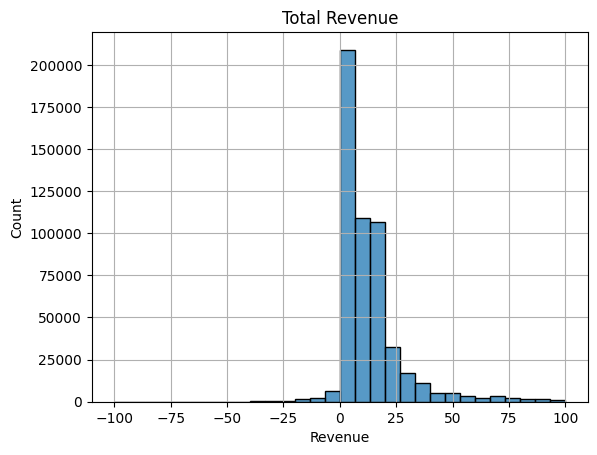

In [72]:
sns.histplot(df_clean.loc[df_clean["Revenue"].between(-100,100), "Revenue"], bins=30)
plt.title("Total Revenue")
plt.xlabel("Revenue")
plt.ylabel("Count")
plt.grid()

### Positive Revenue

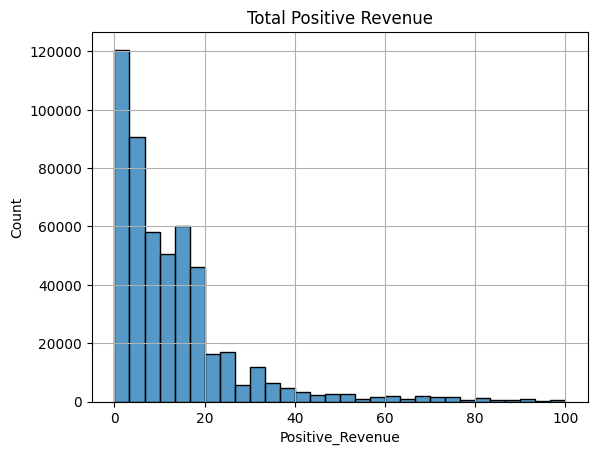

In [73]:
sns.histplot(df_clean.loc[df_clean["Revenue"].between(0, 100), "Revenue"], bins=30)
plt.title("Total Positive Revenue")
plt.xlabel("Positive_Revenue")
plt.ylabel("Count")
plt.grid()

### Quantity Distribution

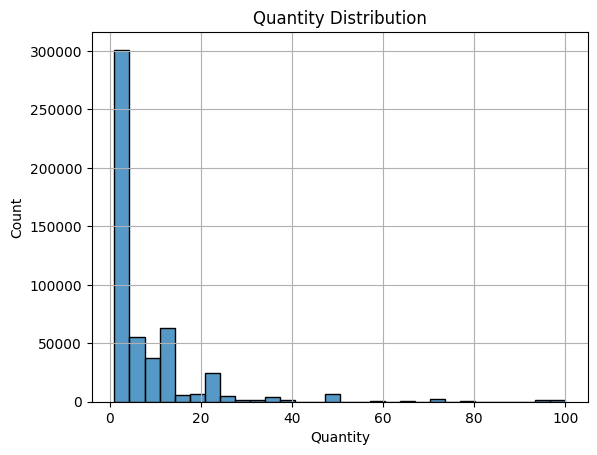

In [74]:
sns.histplot(df_clean.loc[df_clean["Quantity"].between(0, 100), "Quantity"], bins=30)
plt.title("Quantity Distribution")
plt.xlabel("Quantity")
plt.ylabel("Count")
plt.grid()

### Unit price distribution

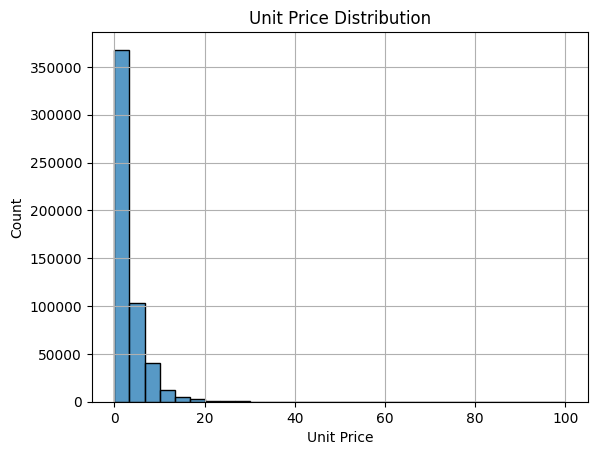

In [75]:
sns.histplot(df_clean.loc[df_clean["UnitPrice"].between(0, 100), "UnitPrice"], bins=30)
plt.title("Unit Price Distribution")
plt.xlabel("Unit Price")
plt.ylabel("Count")
plt.grid()

### Top countries by transaction count

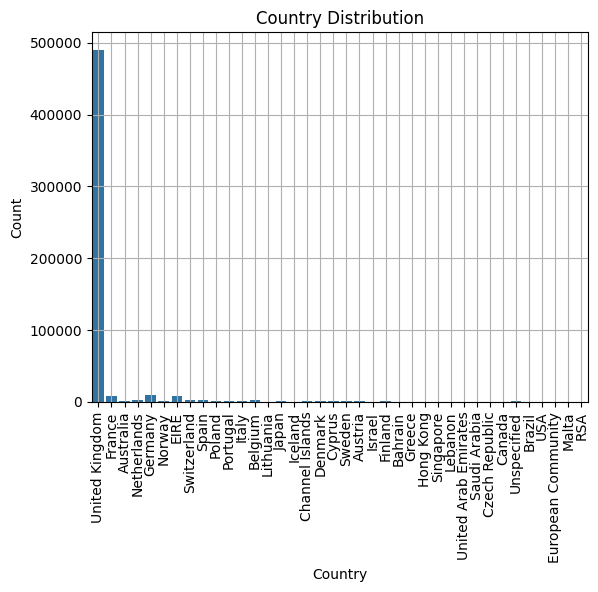

In [76]:
sns.countplot(x = df_clean["Country"])
plt.title("Country Distribution")
plt.xlabel("Country")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.grid()

## Bivariate analysis

### Quantity By Price

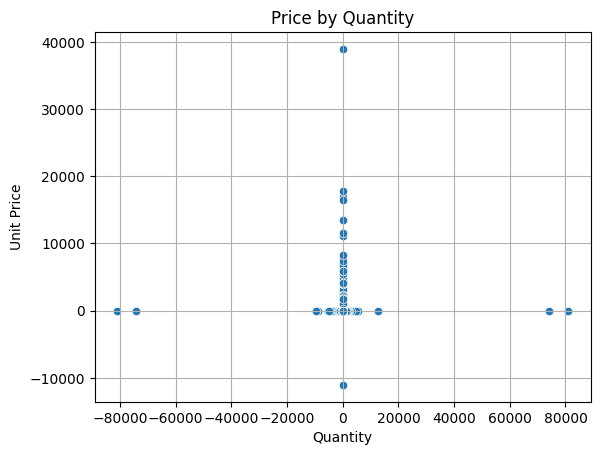

In [77]:
sns.scatterplot(x = df_clean["Quantity"], y = df_clean["UnitPrice"])
plt.title("Price by Quantity")
plt.xlabel("Quantity")
plt.ylabel("Unit Price")
plt.grid()

### Country vs revenue

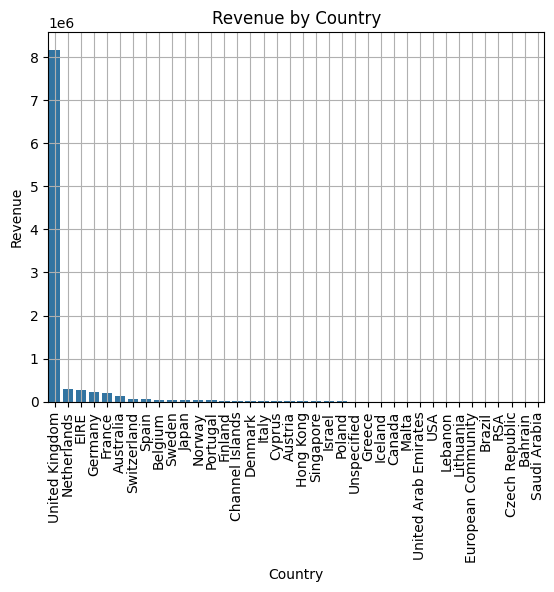

In [78]:
sns.barplot(x=Country_revenue.index, y=Country_revenue.values)
plt.title("Revenue by Country")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=90)
plt.grid()

### Product vs revenue

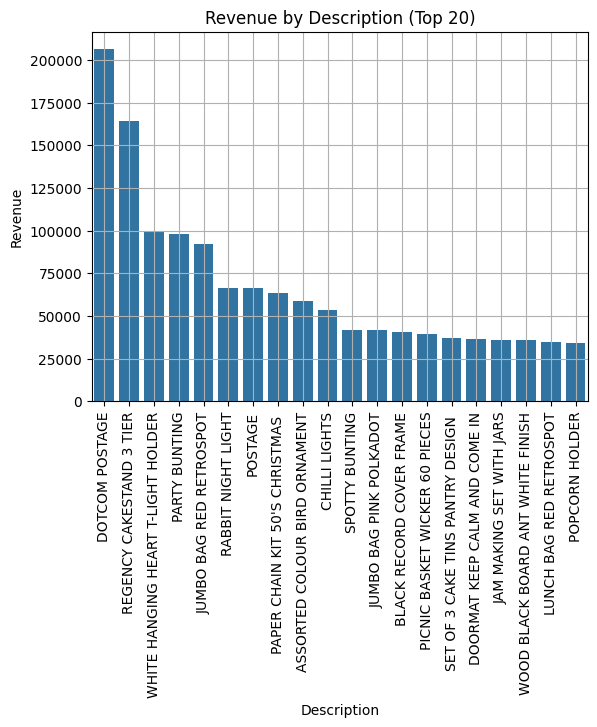

In [79]:
sns.barplot(x = Description_revenue.index, y = Description_revenue.values)
plt.title("Revenue by Description (Top 20)")
plt.xlabel("Description")
plt.ylabel("Revenue")
plt.xticks(rotation=90)
plt.grid()

### Month vs revenue

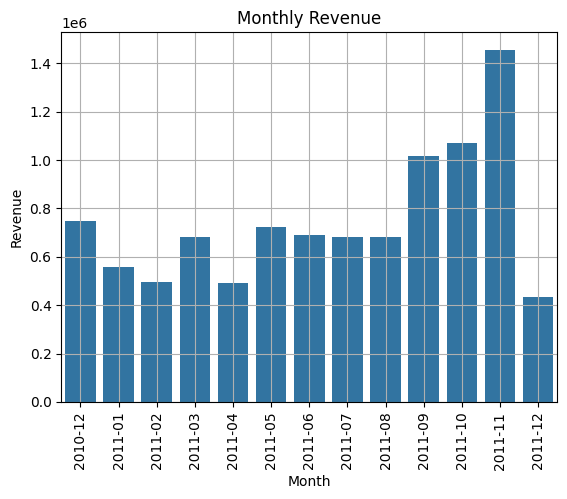

In [121]:
sns.barplot(x = monthly_revenue.index, y = monthly_revenue.values)
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.xticks(rotation=90)
plt.ylabel("Revenue")
plt.grid()

### Top 10 Customers by Revenue

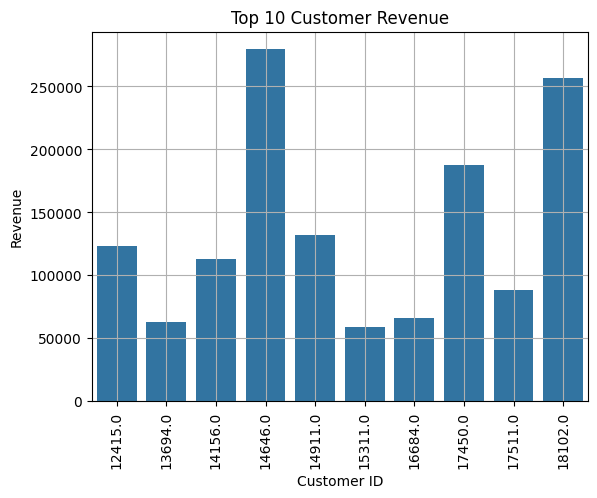

In [114]:
sns.barplot(x = Customer_revenue.index, y = Customer_revenue.values)
plt.title("Top 10 Customer Revenue")
plt.xlabel("Customer ID")
plt.xticks(rotation=90)
plt.ylabel("Revenue")
plt.grid()

## Qutliers

### Quantity

Text(0.5, 0, 'Quantity')

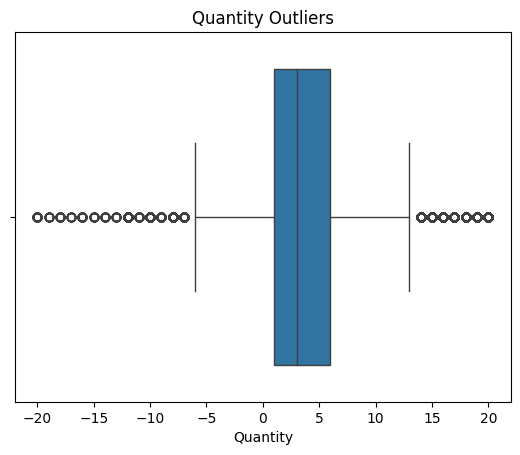

In [82]:
sns.boxplot(x = df_clean.loc[df_clean["Quantity"].between(-20, 20), "Quantity"])
plt.title("Quantity Outliers")
plt.xlabel("Quantity")

In [83]:
Minimum, Q1, Median, Q3, Maximum = np.quantile(df["Quantity"], [0, 0.25, 0.50, 0.75, 1.0])
print("Minimum:", Minimum)
print("Q1:", Q1)
print("Median:", Median)
print("Q3:", Q3)
print("Maximum:", Maximum)

Minimum: -80995.0
Q1: 1.0
Median: 3.0
Q3: 10.0
Maximum: 80995.0


In [84]:
IQR = Q3 - Q1
IQR

np.float64(9.0)

In [85]:
Lower_limit = Q1 - 1.5 * IQR
Lower_limit

np.float64(-12.5)

In [86]:
Upper_limit = Q3 + 1.5 * IQR
Upper_limit

np.float64(23.5)

In [87]:
Quantity_Outliers = df_clean[
    (df["Quantity"] < Lower_limit) |
    (df["Quantity"] > Upper_limit)
]

print("Lower Limit:", Lower_limit)
print("Upper Limit:", Upper_limit)
print("Number of Outliers:", len(Quantity_Outliers))

Lower Limit: -12.5
Upper Limit: 23.5
Number of Outliers: 58501


C:\Users\Aakanksha haravde\AppData\Local\Temp\ipykernel_24200\821052214.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  Quantity_Outliers = df_clean[


### Unit Price

Text(0.5, 0, 'UnitPrice')

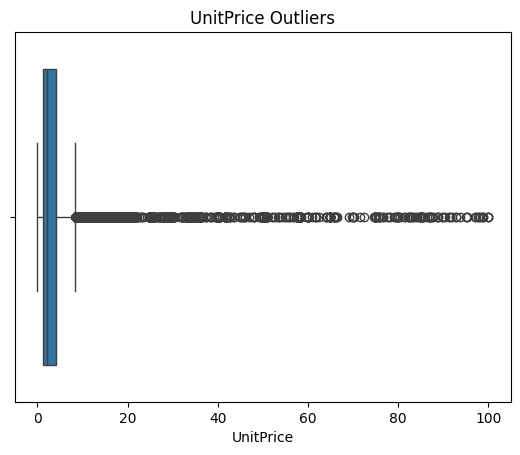

In [88]:
sns.boxplot(x = df_clean.loc[df_clean["UnitPrice"].between(-100, 100), "UnitPrice"])
plt.title("UnitPrice Outliers")
plt.xlabel("UnitPrice")

In [89]:
Minimum, Q1, Median, Q3, Maximum = np.quantile(df_clean["UnitPrice"], [0, 0.25, 0.50, 0.75, 1.0])
print("Minimum:", Minimum)
print("Q1:", Q1)
print("Median:", Median)
print("Q3:", Q3)
print("Maximum:", Maximum)

Minimum: -11062.06
Q1: 1.25
Median: 2.08
Q3: 4.13
Maximum: 38970.0


In [90]:
IQR = Q3 - Q1
IQR

np.float64(2.88)

In [91]:
Lower_limit = Q1 - 1.5 * IQR
Lower_limit

np.float64(-3.0700000000000003)

In [92]:
Upper_limit = Q3 + 1.5 * IQR
Upper_limit

np.float64(8.45)

In [93]:
UnitPrice_Outliers = df_clean[
    (df_clean["UnitPrice"] < Lower_limit) |
    (df_clean["UnitPrice"] > Upper_limit)
]

print("Lower Limit:", Lower_limit)
print("Upper Limit:", Upper_limit)
print("Number of Outliers:", len(UnitPrice_Outliers))

Lower Limit: -3.0700000000000003
Upper Limit: 8.45
Number of Outliers: 39450


In [94]:
df_clean["UnitPrice"].sort_values(ascending=False).head(10)

222681    38970.00
524602    17836.46
43702     16888.02
43703     16453.71
16356     13541.33
15016     13541.33
15017     13541.33
16232     13474.79
524601    11586.50
299982    11062.06
Name: UnitPrice, dtype: float64

In [95]:
df_clean["UnitPrice"].sort_values().head(10) 

299983   -11062.06
299984   -11062.06
481106        0.00
136224        0.00
194638        0.00
281614        0.00
94301         0.00
441505        0.00
204599        0.00
204600        0.00
Name: UnitPrice, dtype: float64

In [99]:
df_clean.loc[
    (df_clean["UnitPrice"] > 0) |
    (df_clean["UnitPrice"] < 1000),
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue", "Country"]
    ].sort_values("UnitPrice").head(20)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue,Country
299983,A563186,B,Adjust bad debt,1,-11062.06,-11062.06,United Kingdom
299984,A563187,B,Adjust bad debt,1,-11062.06,-11062.06,United Kingdom
481106,577339,15060B,NaN,9,0.00,0.00,United Kingdom
136224,547943,21357,NaN,1,0.00,0.00,United Kingdom
194638,553659,20967,NaN,-77,0.00,-0.00,United Kingdom
281614,561553,21392,NaN,-29,0.00,-0.00,United Kingdom
94301,544343,22867,NaN,-99,0.00,-0.00,United Kingdom
441505,574577,21519,check,-80,0.00,-0.00,United Kingdom
204599,554676,71143,NaN,-31,0.00,-0.00,United Kingdom
204600,554677,20664,NaN,9,0.00,0.00,United Kingdom


In [110]:
df_clean["UnitPrice"].describe()

count    536641.000000
mean          4.632656
std          97.233118
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64

In [108]:
# Zero Unit Price
(df_clean["UnitPrice"] == 0).sum()

np.int64(2510)

In [111]:
# Zero UnitPrice with Description
df_clean.loc[df_clean["UnitPrice"] == 0, "Description"].isna().sum()

np.int64(1454)

In [112]:
# Zero UnitPrice with Quantity
df_clean.loc[df_clean["UnitPrice"] == 0, "Quantity"].describe()

count     2510.000000
mean       -53.529880
std        540.739276
min      -9600.000000
25%        -32.750000
50%         -2.000000
75%          3.000000
max      12540.000000
Name: Quantity, dtype: float64

## Key Findings

- **Overall Revenue:** Net revenue was approximately 9.73 million, including 10.64 million from positive-revenue transactions, partly offset by negative-revenue transactions.
- **Country Performance:** The United Kingdom generated the highest revenue at approximately 8.17 million, followed by the Netherlands and EIRE.
- **Product Performance:** DOTCOM POSTAGE had the highest recorded revenue, followed by REGENCY CAKESTAND 3 TIER and WHITE HANGING HEART T-LIGHT HOLDER.
- **Monthly Trends:** November 2011 was the strongest month, with revenue of approximately 1.46 million. December is incomplete because the data ends on 9 December.
- **Customer Performance:** Customer 14646 generated approximately 279,489, followed by customer 18102 at approximately 256,438.
- **Quantity and Price:** Negative values and potential outliers were found. These may represent returns, cancellations, or adjustments rather than errors.

## Business Insights and Recommendations

- Focus on the UK market to understand its strong sales performance.
- Review popular products for inventory and promotional planning, separating postage from physical products.
- Investigate the September–November revenue increase and check whether the pattern repeats in future years.
- Study high-revenue customers' purchase frequency and history before planning retention strategies.
- Review cancellations, returns, zero-price transactions, and unusual prices separately.
- Check potential outliers before removing them to avoid losing valid transaction data.

## Limitations

- Missing CustomerID values limit customer-level analysis.
- The dataset covers approximately one year, limiting long-term and seasonal comparisons.
- December 2011 is incomplete.
- Revenue is not profit because costs and expenses are unavailable.
- Outliers may be valid transactions, and product revenue may include postage or adjustments.

## Conclusion

The analysis identified the UK as the largest revenue market, November 2011 as the strongest month, and several high-revenue products and customers. It also highlighted the importance of handling missing values, cancellations, returns, and outliers carefully. These findings can support better sales and inventory planning.